# Model 2 (Climatological): Location-Aware Solar Viability – XGBoost

**Purpose**: Train a *climatological* XGBoost regression model that predicts **typical solar generation** from spatial–seasonal features (latitude, longitude, month, dry-season flag) using monthly-aggregated NASA POWER data.

**Key Differences vs. Daily Baseline (02-baseline-model-xgboost):**
- Focuses on **monthly averages** (climatology), not noisy daily weather.
- Target is **typical expected daily generation** for a 10m², 20%-efficiency system.
- Training/validation split is by **location**, to test generalisation to unseen cities.

**Target Metric**: MAPE ≤ 15% on held-out *locations* (goal 8–12%).

This notebook mirrors the baseline notebook style but uses the redesigned climatological problem framing aligned with the DSE brief.


In [40]:
# Imports & configuration

import pandas as pd
import numpy as np
from pathlib import Path

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_percentage_error
import matplotlib.pyplot as plt
import seaborn as sns

import sys
from pathlib import Path
sys.path.insert(0, str(Path(".").resolve().parent / "src"))

# Local service module for persistence + prediction helpers
from solar_climatology_service import (
    DRY_MONTHS,
    FEATURE_COLUMNS,
    save_model_artifacts,
    validate_coordinates,
    predict_solar_generation,
    predict_lifetime_generation,
)

plt.style.use('seaborn-v0_8')

# Use generic merged CSV; adjust name if you regenerate exports
DATA_CSV_PATH = Path("solar_data_20cities_4yr.csv")  # relative to notebooks folder
MODEL_TYPE = "XGBoost climatological regression"


In [41]:
# 1. Load merged NASA POWER dataset

if not DATA_CSV_PATH.exists():
    raise FileNotFoundError(
        f"Expected merged solar data CSV at '{DATA_CSV_PATH}', "
        "but it was not found. Run the Nasa_pipeline + cleaning first."
    )

raw_df = pd.read_csv(DATA_CSV_PATH)
print(f"Loaded {len(raw_df):,} daily records from {DATA_CSV_PATH}")
print("Columns:", raw_df.columns.tolist())

# Use only high-quality records
raw_df = raw_df[raw_df["data_quality"] == "good"].copy()
print(f"After quality filter: {len(raw_df):,} records")

raw_df["date"] = pd.to_datetime(raw_df["date"])
raw_df["month"] = raw_df["date"].dt.month

print(raw_df.head())

Loaded 29,200 daily records from solar_data_20cities_4yr.csv
Columns: ['location_name', 'country', 'latitude', 'longitude', 'date', 'year', 'month', 'day', 'day_of_week', 'ghi_kwh_m2', 'clear_sky_ghi_kwh_m2', 'temperature_c', 'wind_speed_ms', 'relative_humidity_pct', 'data_quality']
After quality filter: 29,200 records
         location_name      country  latitude  longitude       date  year  \
0  Abidjan_Ivory_Coast  Ivory Coast      5.36     -4.008 2022-02-22  2022   
1  Abidjan_Ivory_Coast  Ivory Coast      5.36     -4.008 2022-02-23  2022   
2  Abidjan_Ivory_Coast  Ivory Coast      5.36     -4.008 2022-02-24  2022   
3  Abidjan_Ivory_Coast  Ivory Coast      5.36     -4.008 2022-02-25  2022   
4  Abidjan_Ivory_Coast  Ivory Coast      5.36     -4.008 2022-02-26  2022   

   month  day day_of_week  ghi_kwh_m2  clear_sky_ghi_kwh_m2  temperature_c  \
0      2   22     Tuesday      5.3198                6.1186          27.68   
1      2   23   Wednesday      4.7717                5.6292 

In [42]:
# 2. Aggregate to monthly climatology per city

monthly = (
    raw_df.groupby([
        "location_name",
        "country",
        "latitude",
        "longitude",
        "month",
    ], as_index=False)["ghi_kwh_m2"]
    .mean()
    .rename(columns={"ghi_kwh_m2": "avg_ghi_kwh_m2"})
)

# Spatial + seasonal features
monthly["abs_latitude"] = monthly["latitude"].abs()
monthly["is_dry_season"] = monthly["month"].isin(DRY_MONTHS).astype(int)

# Target: typical expected generation for 10m², 20% efficiency
monthly["target_avg_generation_kwh"] = monthly["avg_ghi_kwh_m2"] * 10.0 * 0.2

print(f"Monthly climatology rows: {len(monthly)}")
print("Locations:", sorted(monthly["location_name"].unique()))
print(monthly.head())


Monthly climatology rows: 240
Locations: ['Abidjan_Ivory_Coast', 'Abuja_Nigeria', 'Accra_Ghana', 'Addis_Ababa_Ethiopia', 'Bamako_Mali', 'Cape_Town_SA', 'Dakar_Senegal', 'Dar_es_Salaam_Tanzania', 'Garissa_Kenya', 'Harare_Zimbabwe', 'Johannesburg_SA', 'Kampala_Uganda', 'Kigali_Rwanda', 'Kinshasa_DRC', 'Kumasi_Ghana', 'Lagos_Nigeria', 'Lusaka_Zambia', 'Maputo_Mozambique', 'Mombasa_Kenya', 'Nairobi_Kenya']
         location_name      country  latitude  longitude  month  \
0  Abidjan_Ivory_Coast  Ivory Coast      5.36     -4.008      1   
1  Abidjan_Ivory_Coast  Ivory Coast      5.36     -4.008      2   
2  Abidjan_Ivory_Coast  Ivory Coast      5.36     -4.008      3   
3  Abidjan_Ivory_Coast  Ivory Coast      5.36     -4.008      4   
4  Abidjan_Ivory_Coast  Ivory Coast      5.36     -4.008      5   

   avg_ghi_kwh_m2  abs_latitude  is_dry_season  target_avg_generation_kwh  
0        4.933932          5.36              1                   9.867865  
1        4.777729          5.36        

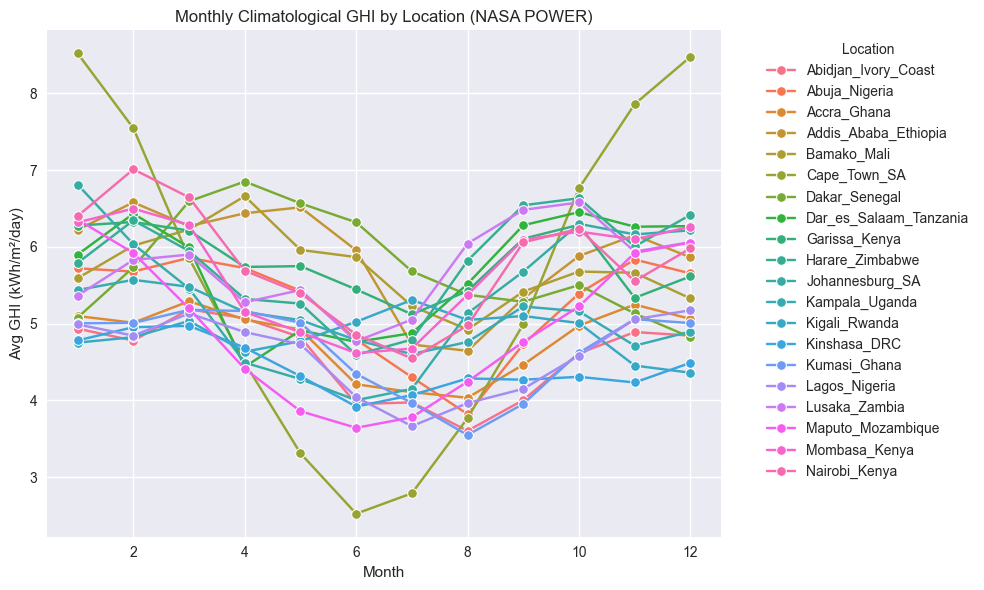

In [43]:
# 3. Visualise monthly GHI patterns by location

fig, ax = plt.subplots(figsize=(10, 6))

sns.lineplot(
    data=monthly,
    x="month",
    y="avg_ghi_kwh_m2",
    hue="location_name",
    marker="o",
    ax=ax,
)

ax.set_title("Monthly Climatological GHI by Location (NASA POWER)")
ax.set_xlabel("Month")
ax.set_ylabel("Avg GHI (kWh/m²/day)")
ax.legend(title="Location", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [44]:
# 4. Train/validation split by LOCATION (spatial generalisation)

all_locations = sorted(monthly["location_name"].unique())
print("All locations:", all_locations)

# Prefer to hold out a mix of climates for validation
preferred_val = ["Johannesburg_SA", "Cape_Town_SA", "Abidjan_Ivory_Coast", "Lusaka_Zambia"]
val_locations = [loc for loc in preferred_val if loc in all_locations]

if not val_locations:
    # Fallback: last 2 alphabetically
    val_locations = all_locations[-2:]

print("\nTrain locations vs Validation locations:")
print("Validation:", val_locations)
train_locations = [loc for loc in all_locations if loc not in val_locations]
print("Train:", train_locations)

train_df = monthly[monthly["location_name"].isin(train_locations)].reset_index(drop=True)
val_df = monthly[monthly["location_name"].isin(val_locations)].reset_index(drop=True)

X_train = train_df[FEATURE_COLUMNS]
y_train = train_df["target_avg_generation_kwh"]

X_val = val_df[FEATURE_COLUMNS]
y_val = val_df["target_avg_generation_kwh"]

print(train_df.head())


All locations: ['Abidjan_Ivory_Coast', 'Abuja_Nigeria', 'Accra_Ghana', 'Addis_Ababa_Ethiopia', 'Bamako_Mali', 'Cape_Town_SA', 'Dakar_Senegal', 'Dar_es_Salaam_Tanzania', 'Garissa_Kenya', 'Harare_Zimbabwe', 'Johannesburg_SA', 'Kampala_Uganda', 'Kigali_Rwanda', 'Kinshasa_DRC', 'Kumasi_Ghana', 'Lagos_Nigeria', 'Lusaka_Zambia', 'Maputo_Mozambique', 'Mombasa_Kenya', 'Nairobi_Kenya']

Train locations vs Validation locations:
Validation: ['Johannesburg_SA', 'Cape_Town_SA', 'Abidjan_Ivory_Coast', 'Lusaka_Zambia']
Train: ['Abuja_Nigeria', 'Accra_Ghana', 'Addis_Ababa_Ethiopia', 'Bamako_Mali', 'Dakar_Senegal', 'Dar_es_Salaam_Tanzania', 'Garissa_Kenya', 'Harare_Zimbabwe', 'Kampala_Uganda', 'Kigali_Rwanda', 'Kinshasa_DRC', 'Kumasi_Ghana', 'Lagos_Nigeria', 'Maputo_Mozambique', 'Mombasa_Kenya', 'Nairobi_Kenya']
   location_name  country  latitude  longitude  month  avg_ghi_kwh_m2  \
0  Abuja_Nigeria  Nigeria     9.076      7.399      1        5.720209   
1  Abuja_Nigeria  Nigeria     9.076      7.399 

In [45]:
# 5. Train XGBoost climatological regression model

model = XGBRegressor(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
)

model.fit(X_train, y_train)

y_val_pred = model.predict(X_val)

mape = mean_absolute_percentage_error(y_val, y_val_pred)
print(f"Validation MAPE (location-based): {mape * 100:.2f}%")

# Enforce DSE acceptance criterion
assert mape <= 0.15, f"MAPE {mape * 100:.2f}% exceeds 15% threshold"


Validation MAPE (location-based): 11.41%


C:\Users\ingex\AppData\Local\Temp\ipykernel_2424\1236302318.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")


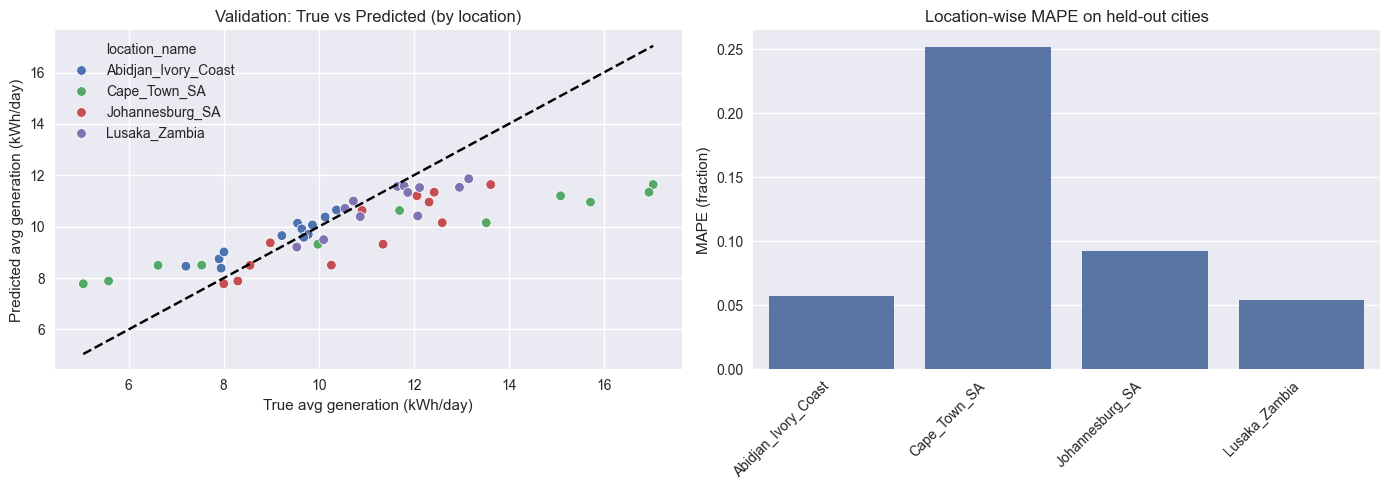

,location_name,abs_pct_error
0,Abidjan_Ivory_Coast,0.057279
1,Cape_Town_SA,0.252249
2,Johannesburg_SA,0.092828
3,Lusaka_Zambia,0.053923


In [46]:
# 6. Visual diagnostics – predictions vs actuals, by location

val_results = val_df.copy()
val_results["y_true"] = y_val
val_results["y_pred"] = y_val_pred
val_results["abs_pct_error"] = (val_results["y_pred"] - val_results["y_true"]).abs() / val_results["y_true"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Scatter: true vs predicted
sns.scatterplot(
    data=val_results,
    x="y_true",
    y="y_pred",
    hue="location_name",
    ax=axes[0],
)
axes[0].plot(
    [val_results["y_true"].min(), val_results["y_true"].max()],
    [val_results["y_true"].min(), val_results["y_true"].max()],
    ls="--",
    color="black",
)
axes[0].set_xlabel("True avg generation (kWh/day)")
axes[0].set_ylabel("Predicted avg generation (kWh/day)")
axes[0].set_title("Validation: True vs Predicted (by location)")

# (b) Bar: MAPE by validation location
mape_by_loc = (
    val_results.groupby("location_name")["abs_pct_error"].mean().reset_index()
)

sns.barplot(
    data=mape_by_loc,
    x="location_name",
    y="abs_pct_error",
    ax=axes[1],
)
axes[1].set_ylabel("MAPE (fraction)")
axes[1].set_xlabel("")
axes[1].set_title("Location-wise MAPE on held-out cities")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")

plt.tight_layout()
plt.show()

mape_by_loc

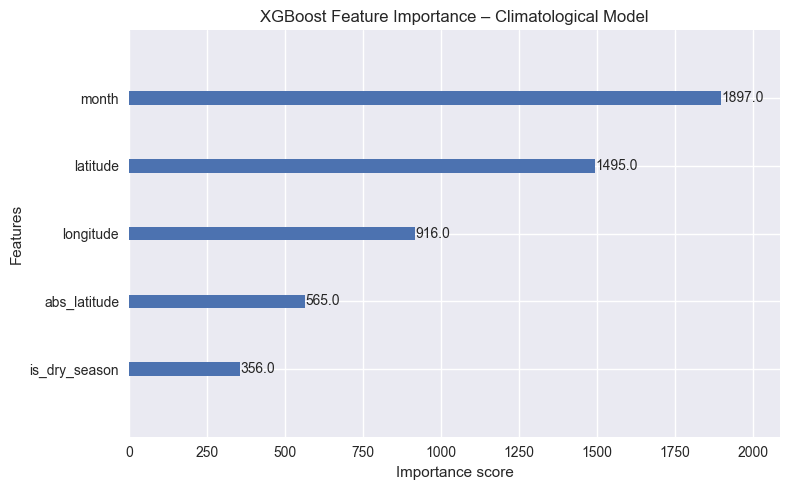

[('latitude', np.float32(0.13229635)),
 ('longitude', np.float32(0.24457377)),
 ('abs_latitude', np.float32(0.36341932)),
 ('month', np.float32(0.19391648)),
 ('is_dry_season', np.float32(0.06579407))]

In [47]:
# 7. Feature importance (why this is ML, not a lookup table)

from xgboost import plot_importance

fig, ax = plt.subplots(figsize=(8, 5))
plot_importance(model, ax=ax)
ax.set_title("XGBoost Feature Importance – Climatological Model")
plt.tight_layout()
plt.show()

list(zip(FEATURE_COLUMNS, model.feature_importances_))

In [48]:
# 8. Save model artifacts directly — no service module dependency

import os, json, joblib
from pathlib import Path
from datetime import datetime

# ── Set this to wherever you want the API to load from ──
SAVE_DIR = Path(r"C:\Users\ingex\OneDrive\Documents\Git Projects\SolarSense AI ML Microservice\Model-1-branch\models\solar_generation\models")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Save model using XGBoost native format (version-safe)
model.save_model(str(SAVE_DIR / "xgboost_climatological_model_v2.json"))

# Save feature columns
joblib.dump(FEATURE_COLUMNS, SAVE_DIR / "feature_columns_v2.pkl")

# Save metadata
metadata = {
    "model_type": "XGBoost climatological regression",
    "created_at_utc": datetime.utcnow().isoformat() + "Z",
    "validation_mape": float(mape),
    "training_locations": sorted(monthly["location_name"].unique().tolist()),
    "feature_columns": FEATURE_COLUMNS,
}
(SAVE_DIR / "xgboost_climatological_metadata_v2.json").write_text(json.dumps(metadata, indent=2))

# Verify immediately
import numpy as np
from xgboost import XGBRegressor
m_check = XGBRegressor()
m_check.load_model(str(SAVE_DIR / "xgboost_climatological_model_v2.json"))
X_test = np.array([[-1.2921, 36.8219, 1.2921, 2, 1]])
print("Nairobi Feb check:", m_check.predict(X_test))  # should be ~11.67
print("Saved to:", SAVE_DIR)

Nairobi Feb check: [11.670187]
Saved to: C:\Users\ingex\OneDrive\Documents\Git Projects\SolarSense AI ML Microservice\Model-1-branch\models\solar_generation\models


C:\Users\ingex\AppData\Local\Temp\ipykernel_2424\457435576.py:20: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "created_at_utc": datetime.utcnow().isoformat() + "Z",


             location_name      mape
0      Abidjan_Ivory_Coast  0.057279
1            Abuja_Nigeria  0.014456
2              Accra_Ghana  0.008165
3     Addis_Ababa_Ethiopia  0.011868
4              Bamako_Mali  0.010225
5             Cape_Town_SA  0.252249
6            Dakar_Senegal  0.007885
7   Dar_es_Salaam_Tanzania  0.012798
8            Garissa_Kenya  0.008182
9          Harare_Zimbabwe  0.016913
10         Johannesburg_SA  0.092828
11          Kampala_Uganda  0.004873
12           Kigali_Rwanda  0.017838
13            Kinshasa_DRC  0.007740
14            Kumasi_Ghana  0.008219
15           Lagos_Nigeria  0.015801
16           Lusaka_Zambia  0.053923
17       Maputo_Mozambique  0.010782
18           Mombasa_Kenya  0.007776
19           Nairobi_Kenya  0.013167


C:\Users\ingex\AppData\Local\Temp\ipykernel_2424\3244924049.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


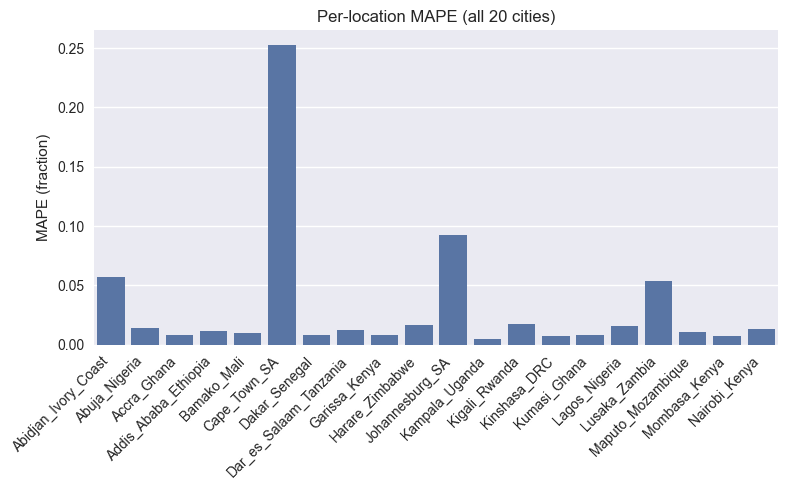

Saved per-location validation chart to outputs\per_location_validation.png


In [49]:
# 9. Per-location validation over all cities (bar chart + PNG)

from pathlib import Path as _Path

outputs_dir = _Path("outputs")
outputs_dir.mkdir(exist_ok=True)

per_loc_results = []

for loc in sorted(monthly["location_name"].unique()):
    df_loc = monthly[monthly["location_name"] == loc]
    X_loc = df_loc[FEATURE_COLUMNS]
    y_loc = df_loc["target_avg_generation_kwh"]
    y_loc_pred = model.predict(X_loc)
    loc_mape = mean_absolute_percentage_error(y_loc, y_loc_pred)
    per_loc_results.append({"location_name": loc, "mape": loc_mape})

per_loc_df = pd.DataFrame(per_loc_results)
print(per_loc_df)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=per_loc_df, x="location_name", y="mape", ax=ax)
ax.set_ylabel("MAPE (fraction)")
ax.set_xlabel("")
ax.set_title("Per-location MAPE (all 20 cities)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()

png_path = outputs_dir / "per_location_validation.png"
plt.savefig(png_path, dpi=150)
plt.show()

print(f"Saved per-location validation chart to {png_path}")


In [50]:
# 10. Demo: point prediction + lifetime projection helpers

lat_demo, lon_demo, month_demo = -1.2921, 36.8219, 6  # Nairobi, June

coord_check = validate_coordinates(lat_demo, lon_demo)
print("Coordinate validation:", coord_check)

pred_daily = predict_solar_generation(lat_demo, lon_demo, month_demo)
print(f"Typical daily generation (month={month_demo}): {pred_daily:.2f} kWh/day")

lifetime = predict_lifetime_generation(lat_demo, lon_demo, lifetime_years=25)
print(
    f"Year 1 generation: {lifetime['year_1_generation_kwh']:.0f} kWh, "
    f"Lifetime total: {lifetime['lifetime_total_kwh']:.0f} kWh",
)

lifetime["year_1_generation_kwh"], lifetime["lifetime_total_kwh"], lifetime["lifetime_average_annual_kwh"]


Coordinate validation: {'status': 'valid', 'warnings': []}
Typical daily generation (month=6): 9.41 kWh/day
Year 1 generation: 3759 kWh, Lifetime total: 86491 kWh


(3759.088422854741, 86490.93220080604, 3459.6372880322415)

In [ ]:
import numpy as np
import xgboost as xgb

m = xgb.Booster()
m.load_model(r"models\solar_generation\models\xgboost_climatological_model_v2.json")

feature_names = ["latitude", "longitude", "abs_latitude", "month", "is_dry_season"]
X = np.array([[-1.89, 36.8219, -1.2921, 2, 1]])
dm = xgb.DMatrix(X, feature_names=feature_names)
print(m.predict(dm))

XGBoostError: [04:01:31] C:\actions-runner\_work\xgboost\xgboost\src\common\io.cc:144: Opening models\solar_generation\models\xgboost_climatological_model_v2.json failed: The system cannot find the path specified.